In [1]:
import os, glob, random, time, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
import cv2

class CFG:
    ROOT        = "/kaggle/input"          # where the competition data is mounted
    TRAIN_CSV   = None                     # auto-found if None
    SAMPLE_CSV  = None                     # auto-found if None
    CLASSES     = ["defect_a", "defect_b", "defect_c", "defect_d"]
    H, W        = 128, 800                 # native size; we do NOT resize (see note in section 5)
    SEED        = 42
    VAL_FRAC    = 0.2
    BATCH_SIZE  = 16
    EPOCHS      = 15
    LR          = 1e-3
    WEIGHT_DECAY= 1e-4
    BASE_CH     = 32                       # U-Net width; 32 -> ~7.8M params
    PATIENCE    = 8                        # early-stopping patience (epochs)
    NUM_WORKERS = 2
    USE_WANDB   = True
    WANDB_PROJECT = "23f1003053-t32026"    # <-- put your real project name
    RUN_NAME    = "unet-scratch-base32"
    OUT_DIR     = "/kaggle/working" if os.path.exists("/kaggle/working") else "."

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu128


In [2]:
def find_first(patterns):
    for p in patterns:
        hits = glob.glob(os.path.join(CFG.ROOT, "**", p), recursive=True)
        if hits: return sorted(hits)[0]
    return None

CFG.TRAIN_CSV  = CFG.TRAIN_CSV  or find_first(["train*.csv"])
CFG.SAMPLE_CSV = CFG.SAMPLE_CSV or find_first(["sample_submission.csv"])
print("train csv :", CFG.TRAIN_CSV)
print("sample csv:", CFG.SAMPLE_CSV)

train csv : /kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
sample csv: /kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv


In [3]:
wandb = None
if CFG.USE_WANDB:
    try:
        import wandb
        try:
            from kaggle_secrets import UserSecretsClient
            wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))
        except Exception:
            wandb.login()          # falls back to env var / interactive prompt
    except Exception as e:
        print("W&B disabled:", e); wandb = None; CFG.USE_WANDB = False

W&B disabled: No API key configured. Use `wandb login` to log in.


In [4]:
df = pd.read_csv(CFG.TRAIN_CSV).fillna("")
print(df.shape); display(df.head(8))
print("images:", df.image_id.nunique())

(45572, 5)


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,,800,128
2,4S22I7SA34,defect_c,,800,128
3,4S22I7SA34,defect_d,,800,128
4,DZ899111OE,defect_a,,800,128
5,DZ899111OE,defect_b,,800,128
6,DZ899111OE,defect_c,,800,128
7,DZ899111OE,defect_d,,800,128


images: 11393


In [5]:
def rle_decode(rle, h=CFG.H, w=CFG.W):
    """RLE string -> (h, w) uint8 mask. 1-indexed, column-major."""
    m = np.zeros(h * w, dtype=np.uint8)
    s = rle.split()
    if len(s):
        starts = np.asarray(s[0::2], dtype=np.int64) - 1      # to 0-indexed
        lens   = np.asarray(s[1::2], dtype=np.int64)
        for a, l in zip(starts, lens):
            m[a:a + l] = 1
    return m.reshape((w, h)).T                                  # column-major -> (h, w)

def rle_encode(mask):
    """(h, w) binary mask -> RLE string. 1-indexed, column-major."""
    flat = np.concatenate([[0], mask.T.reshape(-1), [0]])       # pad so edges produce transitions
    runs = np.where(flat[1:] != flat[:-1])[0] + 1               # 1-indexed transition points
    runs[1::2] -= runs[0::2]                                    # (start, end) -> (start, length)
    return " ".join(map(str, runs))

# Round-trip test: decode(encode(decode(x))) must equal decode(x). If this fails, every submission is wrong.
sample = df[df.mask_rle != ""].sample(200, random_state=0)
for r in sample.mask_rle:
    m = rle_decode(r)
    assert (rle_decode(rle_encode(m)) == m).all()
    assert rle_encode(m) == r.strip(), "re-encoded string differs from original"
print("RLE round-trip OK on 200 masks")

RLE round-trip OK on 200 masks


In [6]:
df["has"] = df.mask_rle.str.strip() != ""
print("Fraction of images containing each defect:"); print(df.groupby("defect_type").has.mean().round(3))
pres = df.pivot(index="image_id", columns="defect_type", values="has")[CFG.CLASSES]
print("\nNumber of defect types per image:"); print(pres.sum(axis=1).value_counts().sort_index())
print("\nCo-occurrence matrix (images containing both):")
print(pres.astype(int).T.dot(pres.astype(int)))

Fraction of images containing each defect:
defect_type
defect_a    0.095
defect_b    0.027
defect_c    0.360
defect_d    0.150
Name: has, dtype: float64

Number of defect types per image:
0    5516
1    4679
2    1072
3     126
Name: count, dtype: int64

Co-occurrence matrix (images containing both):
defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707


In [7]:
# Pixel coverage: how big are defects when present?
df["area"] = df.mask_rle.apply(lambda r: sum(map(int, r.split()[1::2])) if r.strip() else 0)
print(df[df.has].groupby("defect_type").area.describe().round(0))

              count    mean     std   min     25%     50%     75%      max
defect_type                                                               
defect_a     1081.0   749.0   760.0  40.0   251.0   472.0   981.0   7827.0
defect_b      313.0   689.0   409.0  93.0   396.0   620.0   866.0   2992.0
defect_c     4100.0  5558.0  8637.0  32.0  1066.0  2313.0  6277.0  89138.0
defect_d     1707.0  7150.0  6561.0  70.0  2549.0  5143.0  9540.0  50138.0


In [8]:
# Visualise a few defects (needs the image folder; found automatically below)
def find_image_dir(sample_id):
    hits = glob.glob(os.path.join(CFG.ROOT, "**", f"{sample_id}.*"), recursive=True)
    hits = [h for h in hits if h.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))]
    return (os.path.dirname(hits[0]), os.path.splitext(hits[0])[1]) if hits else (None, None)

TRAIN_DIR, TRAIN_EXT = find_image_dir(df.image_id.iloc[0])
print("train images:", TRAIN_DIR, TRAIN_EXT)

train images: /kaggle/input/competitions/industrial-surface-defect-detection/public/train .jpg


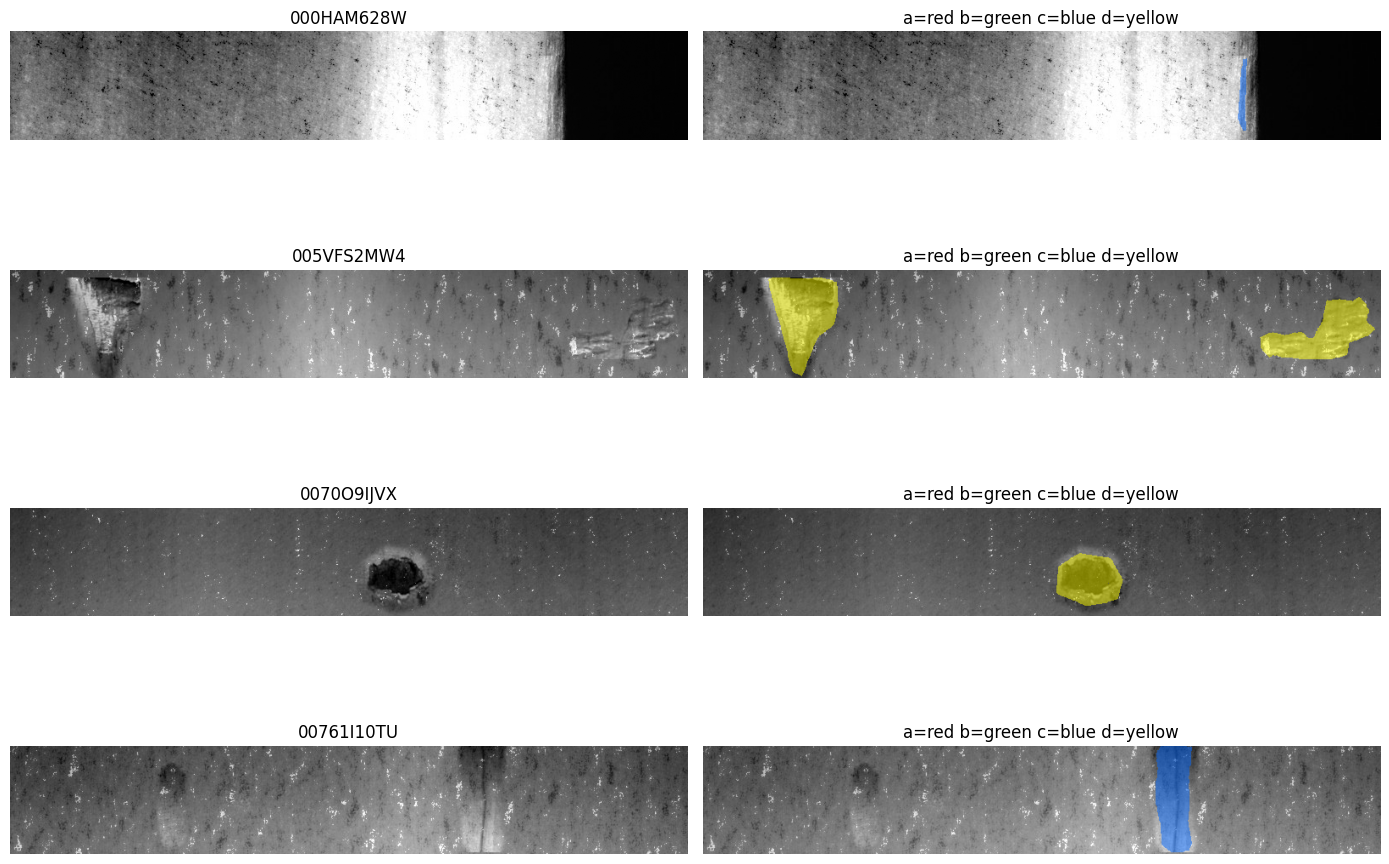

image size: (128, 800) (expected (128, 800) )


In [9]:
def load_gray(path):
    return np.array(Image.open(path).convert("L"), dtype=np.uint8)

rec = {iid: g.set_index("defect_type").mask_rle.to_dict() for iid, g in df.groupby("image_id")}
ids_with_defect = pres[pres.sum(axis=1) > 0].index[:4]
fig, ax = plt.subplots(len(ids_with_defect), 2, figsize=(14, 2.6 * len(ids_with_defect)))
for i, iid in enumerate(ids_with_defect):
    img = load_gray(os.path.join(TRAIN_DIR, iid + TRAIN_EXT))
    masks = np.stack([rle_decode(rec[iid][c]) for c in CFG.CLASSES])
    ax[i, 0].imshow(img, cmap="gray"); ax[i, 0].set_title(iid); ax[i, 0].axis("off")
    overlay = np.stack([img] * 3, -1).astype(np.float32) / 255
    colors = [(1,0,0), (0,1,0), (0,0.4,1), (1,1,0)]
    for k, col in enumerate(colors):
        for ch in range(3): overlay[..., ch] = np.where(masks[k] == 1, 0.5 * overlay[..., ch] + 0.5 * col[ch], overlay[..., ch])
    ax[i, 1].imshow(overlay); ax[i, 1].set_title("a=red b=green c=blue d=yellow"); ax[i, 1].axis("off")
plt.tight_layout(); plt.show()
print("image size:", img.shape, "(expected", (CFG.H, CFG.W), ")")

In [10]:
sig = pres.astype(int).astype(str).agg("".join, axis=1)
counts = sig.value_counts()
sig = sig.where(sig.map(counts) >= 2, "rare")
tr_ids, va_ids = train_test_split(pres.index.values, test_size=CFG.VAL_FRAC, random_state=CFG.SEED, stratify=sig.loc[pres.index].values)
print(len(tr_ids), "train /", len(va_ids), "val")
print("defect rate train:", pres.loc[tr_ids].mean().round(3).values, "| val:", pres.loc[va_ids].mean().round(3).values)

9114 train / 2279 val
defect rate train: [0.095 0.027 0.36  0.15 ] | val: [0.095 0.028 0.36  0.15 ]


In [11]:
class StripDataset(Dataset):
    def __init__(self, ids, img_dir, ext, records=None, train=False):
        self.ids, self.img_dir, self.ext, self.rec, self.train = list(ids), img_dir, ext, records, train
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        iid = self.ids[i]
        img = load_gray(os.path.join(self.img_dir, iid + self.ext)).astype(np.float32) / 255.0
        if self.rec is not None:
            mask = np.stack([rle_decode(self.rec[iid][c]) for c in CFG.CLASSES]).astype(np.float32)
        else:
            mask = np.zeros((len(CFG.CLASSES), CFG.H, CFG.W), np.float32)
        if self.train:
            if random.random() < 0.5: img, mask = img[:, ::-1], mask[:, :, ::-1]
            if random.random() < 0.5: img, mask = img[::-1, :], mask[:, ::-1, :]
            if random.random() < 0.5:                       # brightness / contrast jitter
                a = random.uniform(0.8, 1.2); b = random.uniform(-0.1, 0.1)
                img = np.clip(img * a + b, 0, 1)
        img = (img - 0.5) / 0.5
        return torch.from_numpy(np.ascontiguousarray(img))[None], torch.from_numpy(np.ascontiguousarray(mask))

train_ds = StripDataset(tr_ids, TRAIN_DIR, TRAIN_EXT, rec, train=True)
val_ds   = StripDataset(va_ids, TRAIN_DIR, TRAIN_EXT, rec, train=False)
train_dl = DataLoader(train_ds, CFG.BATCH_SIZE, shuffle=True,  num_workers=CFG.NUM_WORKERS, pin_memory=True, drop_last=True)
val_dl   = DataLoader(val_ds,   CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True)
x, y = next(iter(train_dl)); print("batch:", x.shape, y.shape, x.dtype)   # (16,1,128,800) and (16,4,128,800)

batch: torch.Size([16, 1, 128, 800]) torch.Size([16, 4, 128, 800]) torch.float32


In [12]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNetScratch(nn.Module):
    def __init__(self, in_ch=1, n_classes=4, base=32):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]            # 32, 64, 128, 256, 512
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]),  DoubleConv(c[2], c[3])
        self.bott = DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        self.up4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2); self.dec4 = DoubleConv(c[3]*2, c[3])
        self.up3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2); self.dec3 = DoubleConv(c[2]*2, c[2])
        self.up2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2); self.dec2 = DoubleConv(c[1]*2, c[1])
        self.up1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2); self.dec1 = DoubleConv(c[0]*2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, 1)               # 1x1 conv -> 4 logits per pixel
    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1)); e3 = self.enc3(self.pool(e2)); e4 = self.enc4(self.pool(e3))
        b  = self.bott(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b),  e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)                                    # raw logits (sigmoid applied in loss / inference)

model = UNetScratch(1, 4, CFG.BASE_CH).to(device)
print("parameters: %.2fM" % (sum(p.numel() for p in model.parameters()) / 1e6))
with torch.no_grad(): print("output shape:", model(x[:2].to(device)).shape)   # must be (2, 4, 128, 800)

parameters: 7.76M
output shape: torch.Size([2, 4, 128, 800])


In [13]:
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum((0, 2, 3)); den = p.sum((0, 2, 3)) + target.sum((0, 2, 3))
    return (1 - (2 * inter + eps) / (den + eps)).mean()          # mean over the 4 classes

bce = nn.BCEWithLogitsLoss()
def criterion(logits, target): return 0.5 * bce(logits, target) + 0.5 * dice_loss(logits, target)

def competition_score(pred, gt):
    """pred, gt: binary arrays (N, C, H, W) or (N, H, W). Approximation of the official metric."""
    pred = pred.reshape(pred.shape[0], -1).astype(np.float32); gt = gt.reshape(gt.shape[0], -1).astype(np.float32)
    ps, gs = pred.sum(1), gt.sum(1); inter = (pred * gt).sum(1)
    pos = gs > 0; neg = ~pos
    dice = (2 * inter[pos] / (ps[pos] + gs[pos] + 1e-9)).mean() if pos.any() else 1.0
    fp   = 1 - (ps[neg] / pred.shape[1]).mean() if neg.any() else 1.0
    emp  = (ps[neg] == 0).mean() if neg.any() else 1.0
    return 0.7 * dice + 0.2 * fp + 0.1 * emp, dice, fp, emp

@torch.no_grad()
def predict_probs(model, loader, tta=False):
    model.eval(); out = []
    for xb, _ in loader:
        xb = xb.to(device)
        with torch.autocast(device.type, enabled=(device.type == "cuda")):
            p = torch.sigmoid(model(xb))
            if tta: p = (p + torch.sigmoid(model(xb.flip(-1))).flip(-1)) / 2    # horizontal-flip TTA
        out.append(p.float().cpu().half())
    return torch.cat(out).numpy()                                # (N, 4, H, W) float16

In [14]:
opt = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
val_gt = np.stack([np.stack([rle_decode(rec[i][c]) for c in CFG.CLASSES]) for i in va_ids]).astype(np.uint8)   # (N,4,H,W)

if wandb is not None:
    wandb.init(project=CFG.WANDB_PROJECT, name=CFG.RUN_NAME,
               config={k: v for k, v in vars(CFG).items() if k.isupper() and not k.startswith("_")})

best, bad, best_path = -1, 0, os.path.join(CFG.OUT_DIR, "unet_scratch_best.pt")
for epoch in range(1, CFG.EPOCHS + 1):
    model.train(); t0, run = time.time(), 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device.type, enabled=(device.type == "cuda")):
            loss = criterion(model(xb), yb)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item()
    tr_loss = run / len(train_dl)

    probs = predict_probs(model, val_dl)
    score, dice, fp, emp = competition_score((probs > 0.5).astype(np.uint8), val_gt)
    sched.step(score)
    print(f"ep {epoch:02d} | loss {tr_loss:.4f} | val score {score:.4f} (dice {dice:.3f} fp {fp:.3f} empty {emp:.3f}) | lr {opt.param_groups[0]['lr']:.1e} | {time.time()-t0:.0f}s")
    if wandb is not None:
        wandb.log({"epoch": epoch, "train_loss": tr_loss, "val_score": score, "val_fg_dice": dice,
                   "val_fp_score": fp, "val_empty_acc": emp, "lr": opt.param_groups[0]["lr"]})
    if score > best:
        best, bad = score, 0; torch.save(model.state_dict(), best_path)
    else:
        bad += 1
        if bad >= CFG.PATIENCE: print("early stopping"); break
print("best val score:", round(best, 4))
if wandb is not None: wandb.summary["best_val_score"] = best

/tmp/ipykernel_22/4265849915.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


ep 01 | loss 0.5543 | val score 0.3325 (dice 0.121 fp 0.996 empty 0.489) | lr 1.0e-03 | 159s
ep 02 | loss 0.4798 | val score 0.3725 (dice 0.183 fp 0.997 empty 0.447) | lr 1.0e-03 | 165s
ep 03 | loss 0.4593 | val score 0.4011 (dice 0.220 fp 0.998 empty 0.471) | lr 1.0e-03 | 166s
ep 04 | loss 0.4493 | val score 0.4144 (dice 0.212 fp 0.999 empty 0.662) | lr 1.0e-03 | 166s
ep 05 | loss 0.3913 | val score 0.4160 (dice 0.249 fp 0.998 empty 0.420) | lr 1.0e-03 | 166s
ep 06 | loss 0.3560 | val score 0.4529 (dice 0.280 fp 0.997 empty 0.573) | lr 1.0e-03 | 166s
ep 07 | loss 0.3489 | val score 0.4590 (dice 0.299 fp 0.999 empty 0.503) | lr 1.0e-03 | 167s
ep 08 | loss 0.3454 | val score 0.4614 (dice 0.280 fp 0.999 empty 0.659) | lr 1.0e-03 | 167s
ep 09 | loss 0.3391 | val score 0.4834 (dice 0.318 fp 0.997 empty 0.612) | lr 1.0e-03 | 167s
ep 10 | loss 0.3406 | val score 0.4733 (dice 0.298 fp 0.999 empty 0.652) | lr 1.0e-03 | 167s
ep 11 | loss 0.3363 | val score 0.5027 (dice 0.333 fp 0.999 empty 0.69

In [15]:
def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any(): return mask
    n, lab, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    keep = np.zeros(n, bool); keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= min_area
    return keep[lab].astype(np.uint8)

model.load_state_dict(torch.load(best_path, map_location=device))
val_probs = predict_probs(model, val_dl, tta=True)              # TTA on, so tuning matches final inference
THRS, AREAS = [0.3, 0.4, 0.5, 0.6, 0.7], [0, 50, 100, 200, 400]
best_params = {}
for k, c in enumerate(CFG.CLASSES):
    res = {}
    for t in THRS:
        base = (val_probs[:, k] > t).astype(np.uint8)
        for a in AREAS:
            pm = np.stack([remove_small(m, a) for m in base])
            res[(t, a)] = competition_score(pm, val_gt[:, k])[0]
    (t, a), s = max(res.items(), key=lambda kv: kv[1])
    best_params[c] = (t, a); print(f"{c}: best threshold {t}, min_area {a} -> class score {s:.4f}")

def apply_post(probs):
    out = np.zeros(probs.shape, np.uint8)
    for k, c in enumerate(CFG.CLASSES):
        t, a = best_params[c]
        for i in range(len(probs)): out[i, k] = remove_small((probs[i, k] > t).astype(np.uint8), a)
    return out
final = competition_score(apply_post(val_probs), val_gt)
print("tuned val score: %.4f (dice %.3f fp %.3f empty %.3f)" % final)
if wandb is not None: wandb.summary["tuned_val_score"] = final[0]

defect_a: best threshold 0.3, min_area 50 -> class score 0.4256
defect_b: best threshold 0.3, min_area 0 -> class score 0.3000
defect_c: best threshold 0.3, min_area 100 -> class score 0.5721
defect_d: best threshold 0.3, min_area 100 -> class score 0.6343
tuned val score: 0.5530 (dice 0.422 fp 0.998 empty 0.582)


,class,score,fg_dice,fp_score,empty_acc,n_val_positive
0,defect_a,0.426,0.220,0.999,0.716,216
1,defect_b,0.300,0.000,1.000,1.000,63
2,defect_c,0.572,0.435,0.996,0.687,820
3,defect_d,0.634,0.495,0.997,0.883,342


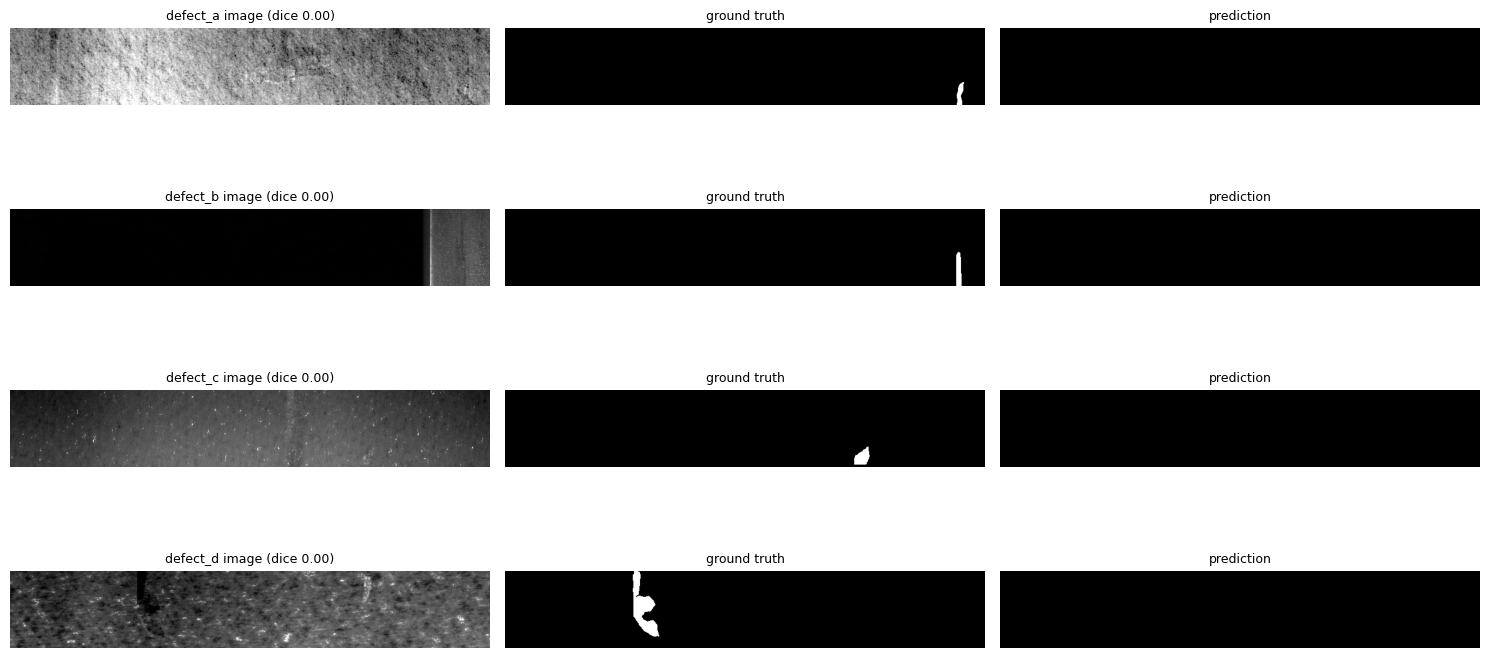

In [16]:
pm = apply_post(val_probs)
rows = []
for k, c in enumerate(CFG.CLASSES):
    s, d, f, e = competition_score(pm[:, k], val_gt[:, k]); rows.append((c, round(s,3), round(d,3), round(f,3), round(e,3), int(val_gt[:, k].reshape(len(va_ids),-1).any(1).sum())))
display(pd.DataFrame(rows, columns=["class", "score", "fg_dice", "fp_score", "empty_acc", "n_val_positive"]))

# worst misses: positive pairs with lowest Dice
fig, ax = plt.subplots(4, 3, figsize=(15, 8))
for r, k in enumerate(range(4)):
    g = val_gt[:, k].reshape(len(va_ids), -1).astype(np.float32); p = pm[:, k].reshape(len(va_ids), -1).astype(np.float32)
    d = np.where(g.sum(1) > 0, 2 * (g * p).sum(1) / (g.sum(1) + p.sum(1) + 1e-9), 9)
    i = int(np.argmin(d)); img = load_gray(os.path.join(TRAIN_DIR, va_ids[i] + TRAIN_EXT))
    for j, (im, t) in enumerate([(img, f"{CFG.CLASSES[k]} image (dice {d[i]:.2f})"), (val_gt[i, k], "ground truth"), (pm[i, k], "prediction")]):
        ax[r, j].imshow(im, cmap="gray"); ax[r, j].set_title(t, fontsize=9); ax[r, j].axis("off")
plt.tight_layout(); plt.show()

In [17]:
sub = pd.read_csv(CFG.SAMPLE_CSV)
test_ids = sub.image_id.unique().tolist()
TEST_DIR, TEST_EXT = find_image_dir(test_ids[0]); print("test images:", TEST_DIR, TEST_EXT, "| n =", len(test_ids))

test_dl = DataLoader(StripDataset(test_ids, TEST_DIR, TEST_EXT, None, train=False), CFG.BATCH_SIZE, shuffle=False, num_workers=CFG.NUM_WORKERS)
test_probs = predict_probs(model, test_dl, tta=True)
test_masks = apply_post(test_probs)

lookup = {(iid, c): rle_encode(test_masks[i, k]) for i, iid in enumerate(test_ids) for k, c in enumerate(CFG.CLASSES)}
sub["mask_rle"] = [lookup[(i, c)] for i, c in zip(sub.image_id, sub.defect_type)]
sub.to_csv(os.path.join(CFG.OUT_DIR, "submission.csv"), index=False)
print(sub.shape, "| fraction non-empty:", (sub.mask_rle != "").mean().round(3))
display(sub.head(8))

test images: /kaggle/input/competitions/industrial-surface-defect-detection/public/test .jpg | n = 3000
(12000, 4) | fraction non-empty: 0.278


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,
5,6,YZXKEWSUDD,defect_b,
6,7,YZXKEWSUDD,defect_c,
7,8,YZXKEWSUDD,defect_d,


In [18]:

assert len(sub) == 12000 and list(sub.columns) == ["ID", "image_id", "defect_type", "mask_rle"]
assert (sub.ID.values == pd.read_csv(CFG.SAMPLE_CSV).ID.values).all()
chk = sub[sub.mask_rle != ""].sample(5, random_state=0)
for r in chk.mask_rle: assert rle_encode(rle_decode(r)) == r
print("submission looks valid")
if wandb is not None: wandb.finish()

submission looks valid
